In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv('data/insurance.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


# EDA 

In [3]:
#EDA 
df.shape

(1338, 7)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [5]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [6]:
df.describe() #Numeric Values - Described 

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
df.isnull().sum() # Checking Null Values

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [8]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

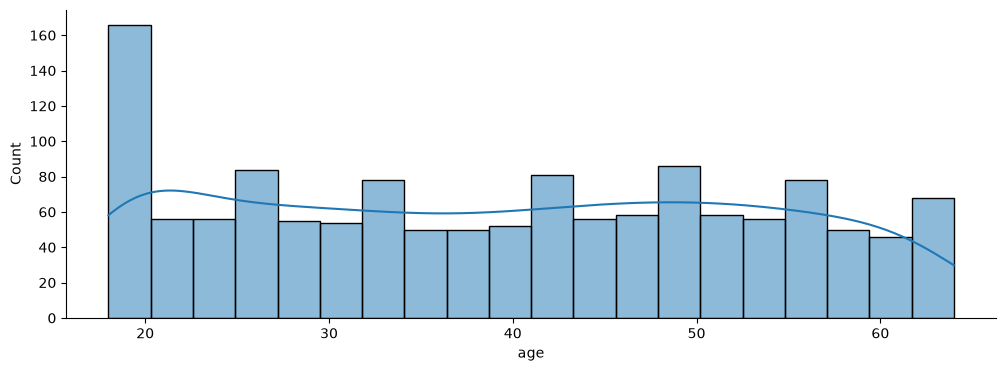

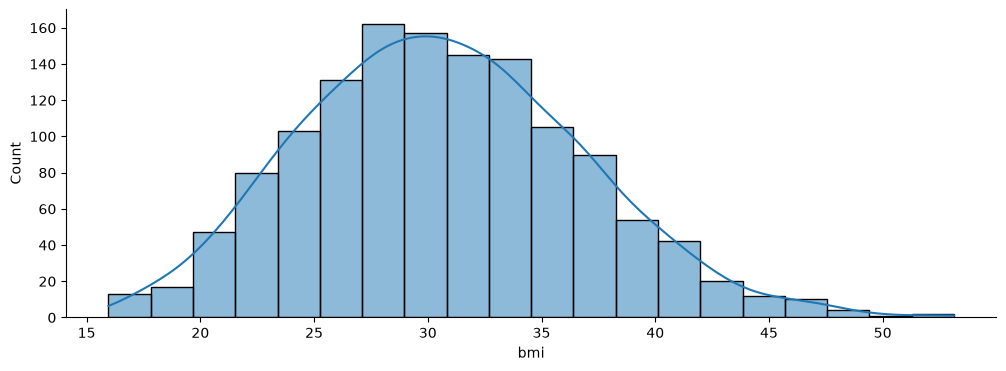

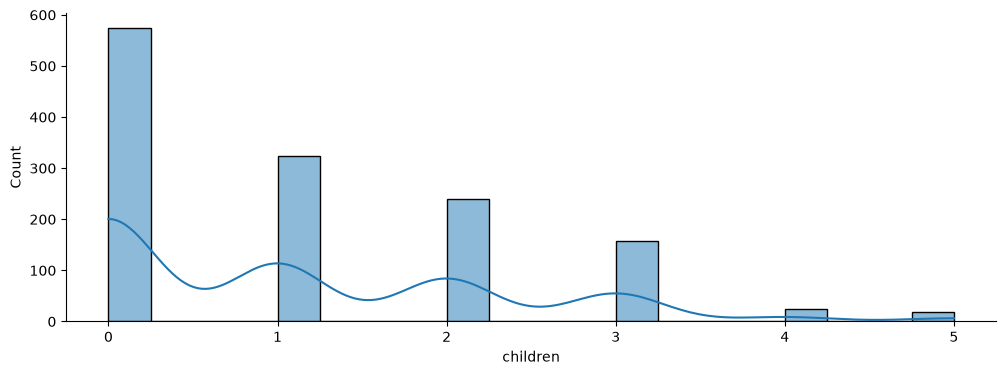

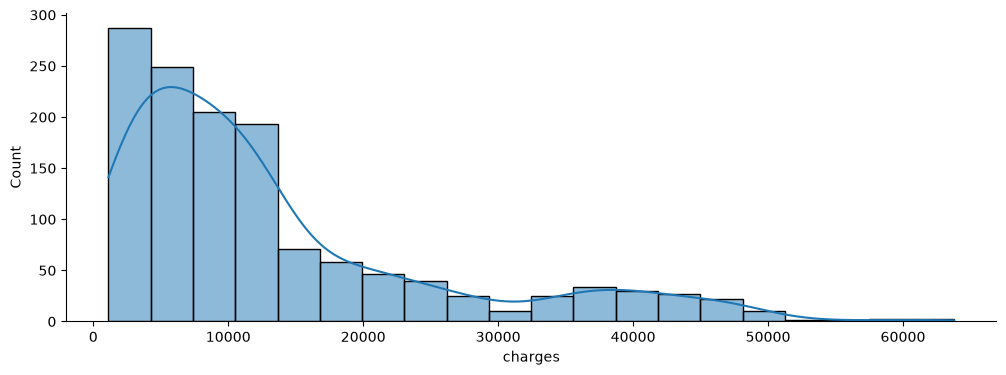

In [9]:
numeric_columns = ['age','bmi','children','charges'] #Distribution Plot

for col in numeric_columns:
    plt.figure(figsize=(12,4))
    sns.histplot(df[col],kde=True,bins=20)
    sns.despine()


<Axes: xlabel='children', ylabel='count'>

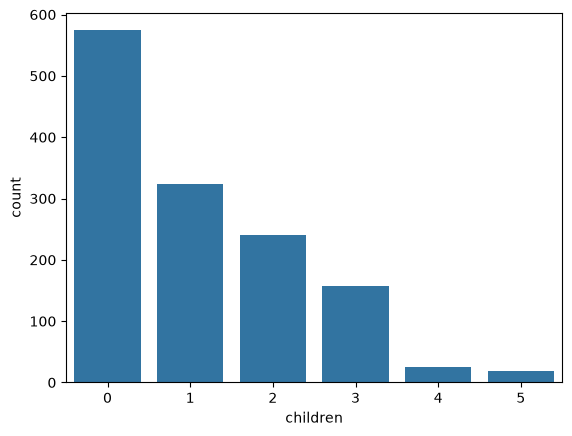

In [10]:
sns.countplot(x=df['children'])

<Axes: xlabel='count', ylabel='sex'>

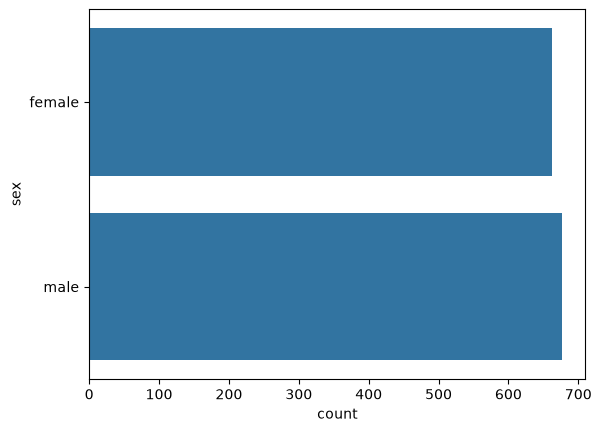

In [11]:
sns.countplot(df['sex'])

<Axes: xlabel='smoker', ylabel='count'>

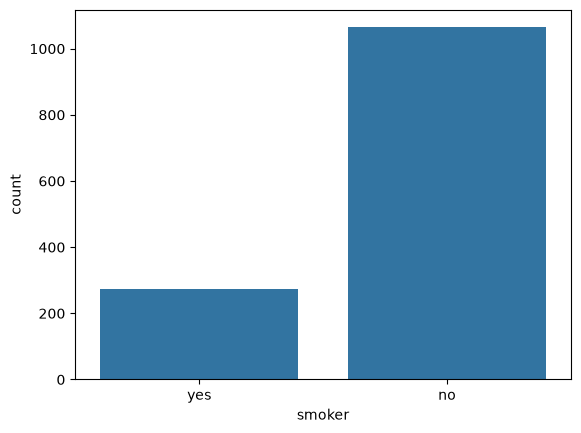

In [12]:
sns.countplot(x=df['smoker'])

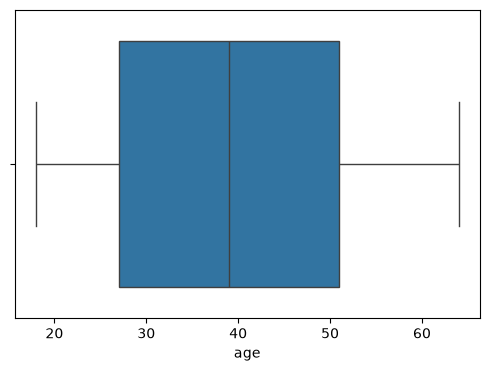

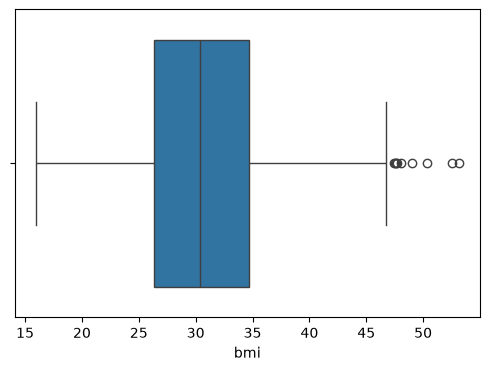

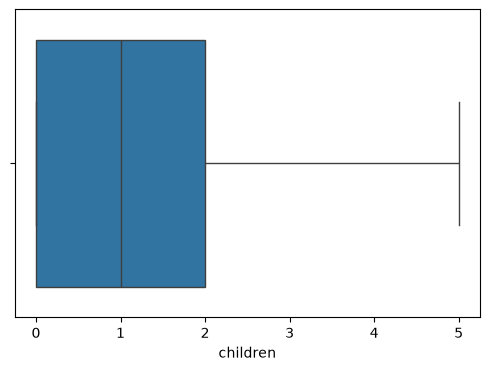

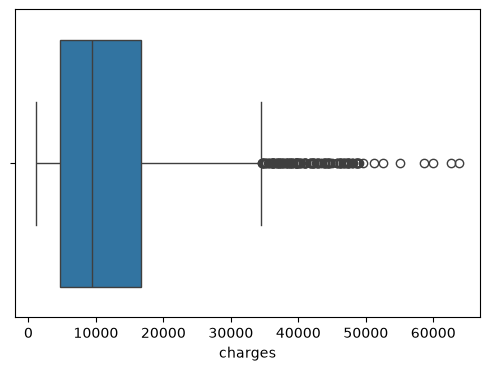

In [13]:
for col in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])

<Axes: >

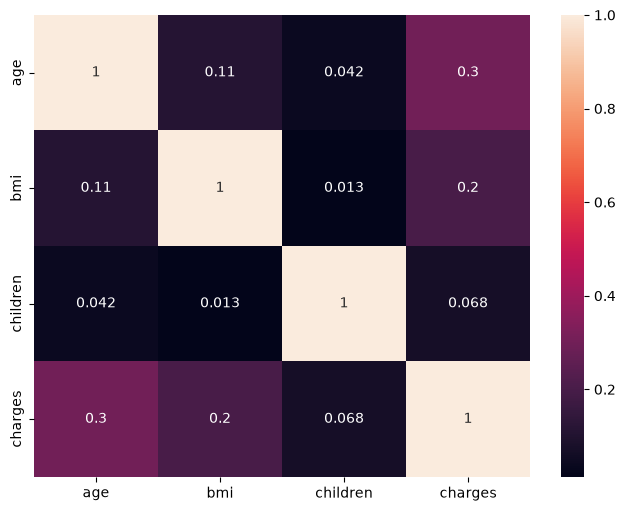

In [14]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)

# Data Cleaning and Preprocessing

In [15]:
df_cleaned = df.copy()
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [16]:
df_cleaned.shape

(1338, 7)

In [17]:
df_cleaned.drop_duplicates(inplace=True)

In [18]:
df_cleaned.shape

(1337, 7)

In [19]:
df_cleaned.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [20]:
df_cleaned.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

In [21]:
df_cleaned['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [22]:
#Label Encoding
df_cleaned['sex'] = df_cleaned['sex'].map({
    'male' : 0,
    'female' : 1
    }
)

df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [23]:
df_cleaned['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [24]:
#Label Encoding
df_cleaned['smoker'] = df_cleaned['smoker'].map({
    'no' : 0,
    'yes' : 1
    }
)

df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [25]:
# Sex & Smoker Renamed
df_cleaned.rename(
    columns = {
        'sex' : 'is_female',
        'smoker' : 'is_smoker'
    },inplace=True
)

df_cleaned

,age,is_female,bmi,children,is_smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,northwest,10600.54830
1334,18,1,31.920,0,0,northeast,2205.98080
1335,18,1,36.850,0,0,southeast,1629.83350
1336,21,1,25.800,0,0,southwest,2007.94500


In [26]:
df['region'].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [27]:
#One Hot Encoding

df_cleaned = pd.get_dummies(df_cleaned,columns=['region'])
df_cleaned.head()


,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,False,True
1,18,0,33.770,1,0,1725.55230,False,False,True,False
2,28,0,33.000,3,0,4449.46200,False,False,True,False
3,33,0,22.705,0,0,21984.47061,False,True,False,False
4,32,0,28.880,0,0,3866.85520,False,True,False,False


In [28]:
df_cleaned = df_cleaned.astype(int)
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,0,1
1,18,0,33,1,0,1725,0,0,1,0
2,28,0,33,3,0,4449,0,0,1,0
3,33,0,22,0,0,21984,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0
1334,18,1,31,0,0,2205,1,0,0,0
1335,18,1,36,0,0,1629,0,0,1,0
1336,21,1,25,0,0,2007,0,0,0,1


# Feature Engineering and Extraction


<Axes: xlabel='bmi', ylabel='Count'>

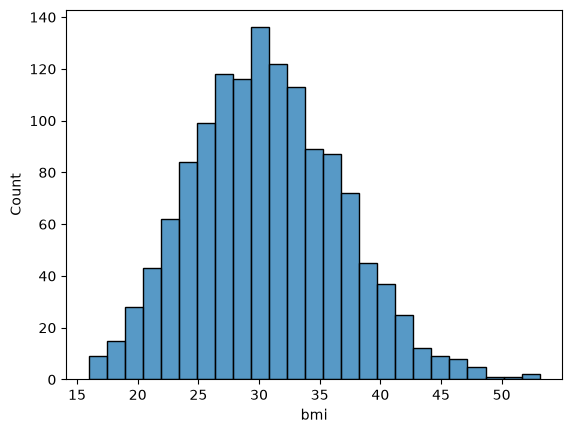

In [29]:
sns.histplot(df['bmi'])

In [30]:
df_cleaned['bmi_category'] = pd.cut(
    df_cleaned['bmi'],
    bins = [0,18.5,24.9,29.9,float('inf')],
    labels =  ['Underweight','Normal','Overweight','Obese']
)

df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27,0,1,16884,0,0,0,1,Overweight
1,18,0,33,1,0,1725,0,0,1,0,Obese
2,28,0,33,3,0,4449,0,0,1,0,Obese
3,33,0,22,0,0,21984,0,1,0,0,Normal
4,32,0,28,0,0,3866,0,1,0,0,Overweight
...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0,Obese
1334,18,1,31,0,0,2205,1,0,0,0,Obese
1335,18,1,36,0,0,1629,0,0,1,0,Obese
1336,21,1,25,0,0,2007,0,0,0,1,Overweight


In [31]:
#One Hot encoding
df_cleaned = pd.get_dummies(df_cleaned,columns=['bmi_category'])
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27,0,1,16884,0,0,0,1,False,False,True,False
1,18,0,33,1,0,1725,0,0,1,0,False,False,False,True
2,28,0,33,3,0,4449,0,0,1,0,False,False,False,True
3,33,0,22,0,0,21984,0,1,0,0,False,True,False,False
4,32,0,28,0,0,3866,0,1,0,0,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0,False,False,False,True
1334,18,1,31,0,0,2205,1,0,0,0,False,False,False,True
1335,18,1,36,0,0,1629,0,0,1,0,False,False,False,True
1336,21,1,25,0,0,2007,0,0,0,1,False,False,True,False


In [32]:
df_cleaned = df_cleaned.astype(int)
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27,0,1,16884,0,0,0,1,0,0,1,0
1,18,0,33,1,0,1725,0,0,1,0,0,0,0,1
2,28,0,33,3,0,4449,0,0,1,0,0,0,0,1
3,33,0,22,0,0,21984,0,1,0,0,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0,0,0,1,0


In [33]:
df_cleaned.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
       'bmi_category_Overweight', 'bmi_category_Obese'],
      dtype='str')

In [34]:
from sklearn.preprocessing import StandardScaler
cols = ['age','bmi','children']

#Standard Scaling
scaler = StandardScaler()

df_cleaned[cols] = scaler.fit_transform(df_cleaned[cols])


In [35]:
df_cleaned.sample(5)

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
345,-0.371972,1,-0.191145,1.580143,0,6184,0,0,1,0,0,0,1,0
225,1.123853,0,0.462463,1.580143,0,11987,0,0,1,0,0,0,0,1
801,1.764921,1,0.789267,-0.909234,0,14313,0,0,1,0,0,0,0,1
1037,0.411556,1,-0.027743,-0.079442,1,39725,0,1,0,0,0,0,0,1
773,-1.440418,1,-0.354547,-0.909234,1,17748,0,1,0,0,0,0,1,0


                     feature  pearson_corr_with_charges
0                  is_smoker                   0.787234
1                        age                   0.298309
2         bmi_category_Obese                   0.200348
3                        bmi                   0.196236
4           region_southeast                   0.073577
5                   children                   0.067390
6           region_northeast                   0.005946
7           region_northwest                  -0.038695
8           region_southwest                  -0.043637
9   bmi_category_Underweight                  -0.050599
10                 is_female                  -0.058046
11       bmi_category_Normal                  -0.104042
12   bmi_category_Overweight                  -0.120601


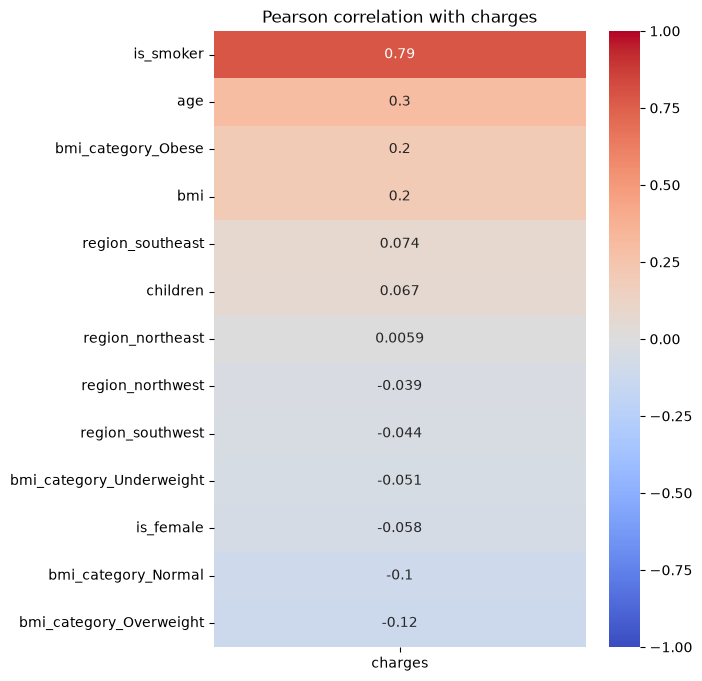

In [36]:
# Pearson correlation of every feature with charges
charges_corr = (
    df_cleaned.corr(method='pearson')['charges']
    .drop('charges')
    .sort_values(ascending=False)
)

correlation_df = charges_corr.rename_axis('feature').reset_index(name='pearson_corr_with_charges')
print(correlation_df)

plt.figure(figsize=(6,8))
sns.heatmap(charges_corr.to_frame('charges'), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Pearson correlation with charges')
plt.show()

In [37]:
correlation_df['feature'].tolist()

['is_smoker',
 'age',
 'bmi_category_Obese',
 'bmi',
 'region_southeast',
 'children',
 'region_northeast',
 'region_northwest',
 'region_southwest',
 'bmi_category_Underweight',
 'is_female',
 'bmi_category_Normal',
 'bmi_category_Overweight']

In [38]:
# Chi-square test of independence: each feature vs. charges
# (charges is continuous, so it is binned into quartiles first)
from scipy.stats import chi2_contingency

cat_features = correlation_df['feature'].tolist()

charges_bin = pd.qcut(df_cleaned['charges'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])

results = []
for col in cat_features:
    contingency = pd.crosstab(df_cleaned[col], charges_bin)
    chi2, p, dof, expected = chi2_contingency(contingency)
    results.append({
        'feature': col,
        'chi2': chi2,
        'dof': dof,
        'p_value': p,
        'significant (p<0.05)': p < 0.05
    })

chi_df = pd.DataFrame(results).sort_values('p_value').reset_index(drop=True)
chi_df

,feature,chi2,dof,p_value,significant (p<0.05)
0,age,1509.130250,138,4.230603e-229,True
1,is_smoker,848.219178,3,1.507478e-183,True
2,children,138.659313,15,4.230749e-22,True
3,region_southeast,15.998167,3,1.134966e-03,True
4,is_female,10.258784,3,1.648974e-02,True
5,bmi,144.758888,111,1.727841e-02,True
6,bmi_category_Obese,8.515711,3,3.647336e-02,True
7,region_northeast,6.438442,3,9.212206e-02,False
8,region_southwest,5.091893,3,1.651906e-01,False
9,bmi_category_Overweight,4.251490,3,2.355571e-01,False
